In [ ]:
#импортируем необходимые библиотеки для работы
import numpy as np
from PIL import Image
import math
import matplotlib.pyplot as plt
from matplotlib.pyplot import figure

Мера яркостного контраста

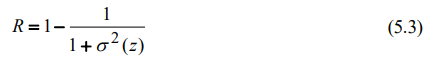

Мера однородности, оценивающая равномерность гистограммы:

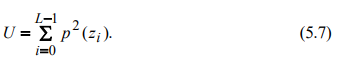

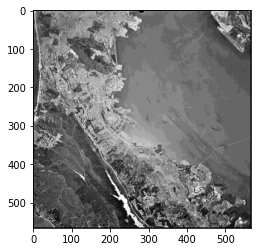

In [ ]:
img = Image.open(r"/content/drive/MyDrive/3sem/MIOI/lab5.png")
# img = np.mean(img, axis=-1)
gray_img = np.array(img.convert("L") )
plt.imshow(gray_img, cmap='gray')

In [ ]:
def get_texture(gray_image_array,mask_size, type):

    # Retrieve dimensions from gray_image_array's shape.
    (H, W) = gray_image_array.shape
    # Retrieve dimensions from the mask .
    f = mask_size

    pad = int((f - 1)/2)

 
    out_image = np.ones((H, W))
    
    gray_image_array_pad = np.pad(gray_image_array, ((pad,pad), (pad,pad)), mode='constant', constant_values = (0,0))
    for h in range(H):          
      for w in range(W):       
                   
        gray_image_array_slice= gray_image_array_pad[h:h+f, w:w+f]
        flatt = gray_image_array_slice.flatten()

        #мера яркостного контраста
        if type == 1:
          std = np.std(flatt)
          out_image[h, w] = (1- (1 / (1 + std**2)))
        
        #мера однородности
        if type == 2:
          uniq = list(set(flatt))
          re = []
          for i in uniq:
            p = list(flatt).count(i) / len(flatt)#probabilities
            p_p = p ** 2
            re.append(p_p)
          out_image[h, w] = sum(re)
        
    return out_image

In [ ]:
tex1_9 = get_texture(gray_img, 9,1)
tex2_9 = get_texture(gray_img, 9,2)

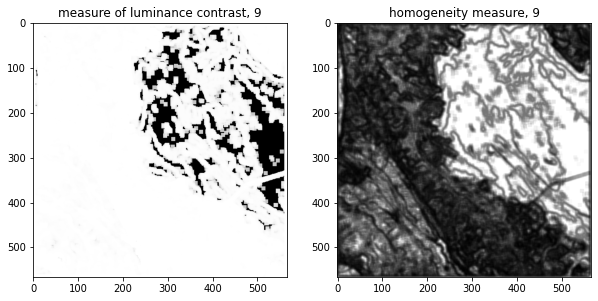

In [ ]:
fig, axs = plt.subplots(nrows = 1, ncols=2, figsize = (10, 10))
axs[0].title.set_text('measure of luminance contrast, 9')
axs[0].imshow(tex1_9, cmap='gray')
axs[1].title.set_text('homogeneity measure, 9')
axs[1].imshow(tex2_9, cmap='gray')

In [ ]:
tex1_7 = get_texture(gray_img, 7,1)
tex2_7 = get_texture(gray_img, 7,2)

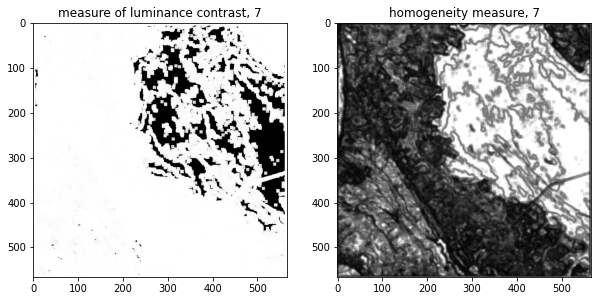

In [ ]:
fig, axs = plt.subplots(nrows = 1, ncols=2, figsize = (10, 10))
axs[0].title.set_text('measure of luminance contrast, 7')
axs[0].imshow((tex1_7), cmap='gray')
axs[1].title.set_text('homogeneity measure, 7')
axs[1].imshow((tex2_7), cmap='gray')

In [ ]:
tex1_5 = get_texture(gray_img, 5,1)
tex2_5 = get_texture(gray_img, 5,2)

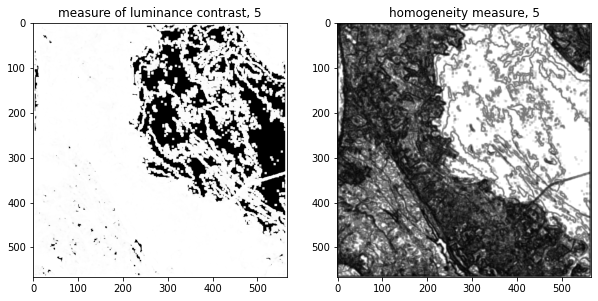

In [ ]:
fig, axs = plt.subplots(nrows = 1, ncols=2, figsize = (10, 10))
axs[0].title.set_text('measure of luminance contrast, 5')
axs[0].imshow((tex1_5), cmap='gray')
axs[1].title.set_text('homogeneity measure, 5')
axs[1].imshow((tex2_5), cmap='gray')

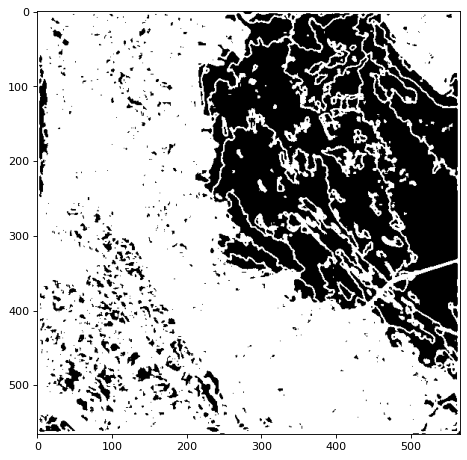

In [ ]:
from skimage import filters
val = filters.threshold_otsu(tex2_5)

arr = np.zeros(tex2_5.shape).astype('int')
for i in range(tex2_5.shape[0]):
  for j in range(tex2_5.shape[1]):
    if tex2_5[i,j] > val:
      arr[i, j] = int(0)
    else:
      arr[i, j] = int(1)
figure(figsize=(7, 7), dpi=80)
plt.imshow(arr, cmap='gray')

In [ ]:

def remove_small_ob(arr, min_size=64):
  ar = arr.copy()
  out = arr.copy()
  lir = [x for x in range(2, 10000000)]
  lir.reverse()
  for i in range(ar.shape[0]):
    for j in range(ar.shape[1]):
      
      re = []
      if ar[i,j]==0:
        continue
      else:
        if i-1 != -1 and j-1 !=-1:
          
          n1 = ar[i-1,j-1]
          re.append(n1)
        if i-1 !=-1:
          n2 = ar[i-1,j]
          re.append(n2)
        if i-1 !=-1 and j+1 <= ar.shape[1]-1:
          n3 = ar[i-1,j+1]
          re.append(n3)
        if j-1 != -1 :
          n4 = ar[i,j-1]
          re.append(n4) 
        if j+1 <= ar.shape[1]-1 :
          n5 = ar[i,j+1]
          re.append(n5)
        if i+1 <= ar.shape[0]-1 and j-1 !=-1:
          n6 = ar[i+1,j-1] 
          re.append(n6)
        if i+1 <= ar.shape[0]-1:
          n7 = ar[i+1,j]
          re.append(n7) 
        if i+1 <= ar.shape[0]-1 and j+1 <=ar.shape[1]-1:
          n8 = ar[i+1,j+1] 
          re.append(n8)   
        
        
        if not all(i == 1 or i == 0 for i in re):
          re2 = []
          for z in re:
            if z>1:
              re2.append(z)
          d = np.min(re2)

        else:
          d = lir.pop()

          
        ar[i, j] = d

  component_sizes = np.bincount(ar.ravel())
  print(component_sizes[0])
  for x in range(ar.shape[0]):
    for y in range(ar.shape[1]):
      if component_sizes[ar[x,y]] < min_size:

        if out[x,y] == 1:
          out[x,y] = 0

  return out


107350


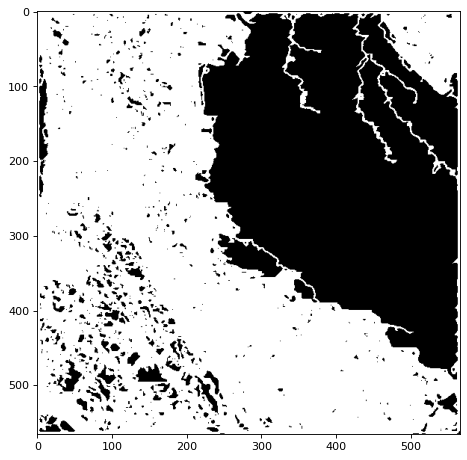

In [ ]:

out1 = remove_small_ob(arr, min_size=13350)
figure(figsize=(7, 7), dpi=80)
plt.imshow(out1, cmap='gray')

191939


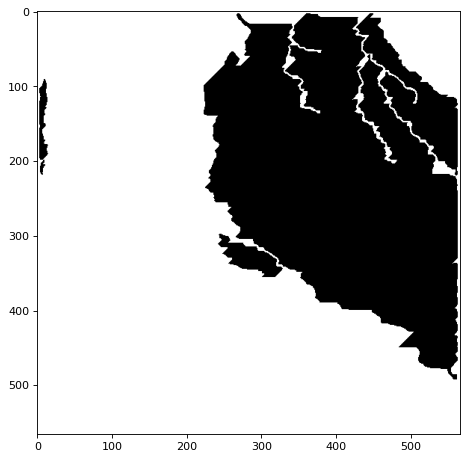

In [ ]:
out2 = out1.copy()
out2 = np.logical_not(out2)
out2 = np.array(out2).astype(int)
out2 = remove_small_ob(out2, min_size=700)
out2 = np.logical_not(out2)
figure(figsize=(7, 7), dpi=80)
plt.imshow(out2, cmap='gray')

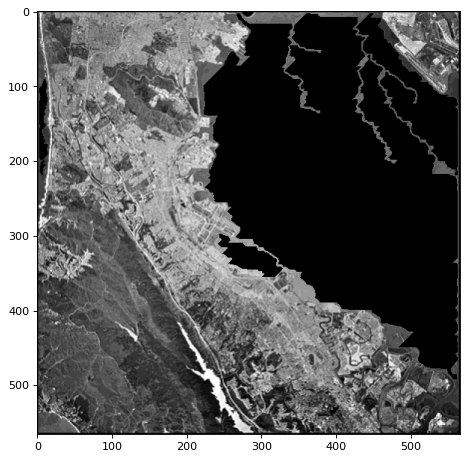

In [ ]:
figure(figsize=(7, 7), dpi=80)
d = gray_img * out2
plt.imshow(d, cmap='gray')